In [1]:
import matplotlib.pyplot as plt  # 导入matplotlib库用于绘制图形
from mpl_toolkits.mplot3d import Axes3D  # 导入3D绘图工具包
import numpy as np  # 导入numpy库用于数组和数值计算
import pandas as pd
import matplotlib.cm as cm  # 导入matplotlib的颜色映射模块
import matplotlib.colors as mcolors  # 导入颜色规范模块
from mpl_toolkits.mplot3d.art3d import Poly3DCollection  # 导入3D多边形集合，用于填充区域
from matplotlib.font_manager import FontProperties
# font = FontProperties(fname = 'Times_New_Roman.ttf', size = 14)
font = FontProperties(fname='Times_New_Roman.ttf', size=14)

In [2]:
def plot_3d(df, path1 = None, path2 = None, mode = None, lam = 20, fontsize = 12, fontsize2 = 10, figure_show = False):
    epochs = list(np.unique(df.index))
    batch_sizes = list(df.columns)  # np.linspace(0, 1, num = 6)

    for j in range(len(n_list)):
        accuracies = np.array(df.iloc[list(range(j * 11, 11 + j * 11)), ]).T
        X, Y = np.meshgrid(epochs, batch_sizes)  # 创建X-Y网格
        Z = np.array(accuracies)  # 将准确率数据转化为numpy数组
        show_epochs2 = epochs
        # 绘制3D图形
        fig = plt.figure(figsize=(12, 10))  # 创建一个10x8英寸的图形
        ax = fig.add_subplot(111, projection='3d')  # 添加3D坐标轴
        # 创建颜色映射
        norm = mcolors.Normalize(vmin=min(batch_sizes),
                                 vmax=max(batch_sizes))  # 归一化batch size，用于颜色映射
        cmap = cm.viridis  # 使用viridis颜色映射
        # 设置统一的线宽
        line_width = 1.0  # 统一的线宽设置
        # 绘制每个batch size的折线
        for i, batch_size in enumerate(batch_sizes):  # 循环遍历每个batch size
            # 绘制批次大小对应的3D曲线
            ax.plot(epochs, [batch_size] * len(epochs),
                    accuracies[i],
                    label=f'Batch Size {batch_size}',
                    color=cmap(norm(batch_size)),
                    linewidth=line_width)

            # 画出折线在平面上的投影
            ax.plot(epochs, [batch_size] * len(epochs),
                    np.zeros(len(epochs)),
                    color=cmap(norm(batch_size)),
                    linewidth=line_width)

            # 创建用于填充的多边形顶点
            verts = [(x, batch_size, z)
                     for x, z in zip(epochs, accuracies[i])]  # 曲线上的顶点坐标
            verts += [(x, batch_size, 0) for x in epochs[::-1]]  # XY平面上的顶点 (Z=0)

            # 使用 Poly3DCollection 填充曲线与 XY 平面之间的区域
            poly = Poly3DCollection([verts], color=cmap(norm(batch_size)),
                                    alpha=0.2)  # 创建半透明填充区域
            ax.add_collection3d(poly)  # 将填充区域添加到图形中

        # 添加颜色条
        # mappable = cm.ScalarMappable(norm=norm, cmap=cmap)  # 创建颜色映射器
        # mappable.set_array(batch_sizes)  # 设置颜色映射的数据范围
        # fig.colorbar(mappable, ax=ax, shrink=0, aspect=0)  # 添加颜色条，调整大小和形状
        # 如果图例已生成，可以用以下方法移除
        plt.legend().remove()  # 不显示图例
        # 在特定的epoch上展示点和数值
        for epoch in show_epochs2:  # 遍历需要重点展示的epoch
            data_list_x = []  # 存储epoch的数据
            data_list_y = []  # 存储batch size的数据
            data_list_z = []  # 存储准确率数据
            for i, batch_size in enumerate(batch_sizes):  # 遍历每个batch size
                # 绘制重点的散点图，突出显示
                ax.scatter(epoch,
                           batch_size,
                           accuracies[i][epochs.index(epoch)],
        #                        color=cmap(norm(batch_size)),
                           s=20,
                           edgecolor='black',
                           zorder=10)
                # 在散点旁边显示数值
                #         ax.text(epoch, batch_size, accuracies[i][epochs.index(epoch)], f'{accuracies[i][epochs.index(epoch)]:.2f}', color='black', zorder=10)
                data_list_x.append(epoch)  # 记录当前的epoch
                data_list_y.append(batch_size)  # 记录当前的batch size
                data_list_z.append(accuracies[i][epochs.index(epoch)])  # 记录当前的准确率
            # 绘制每个特定epoch下的虚线连接不同batch size的准确率
            ax.plot(data_list_x,
                    data_list_y,
                    data_list_z,
                    color='black',
                    linewidth=line_width,
                    linestyle='--')

        # 定义直线的起点和终点
        P1 = np.array([epochs[0], 0, 0.05])  # 起点
        P2 = np.array([epochs[-1], 0, 0.05])  # 终点

        # 计算直线的参数化方程
        t = np.linspace(0, 1, 100)
        x = P1[0] + (P2[0] - P1[0]) * t
        y = P1[1] + (P2[1] - P1[1]) * t
        z = P1[2] + (P2[2] - P1[2]) * t
        # 绘制直线
        ax.plot(x, y, z, label='Line in 3D', color='red')
        # 设置坐标轴标签
        ax.set_xticks(epochs)
        ax.set_xticklabels(ax.get_xticklabels(), rotation=45)
        ax.set_yticks(batch_sizes)
        ax.xaxis.set_tick_params(pad=-5)
        ax.yaxis.set_tick_params(pad=-1)
        ax.zaxis.set_tick_params(pad=-1)
        ax.set_xlabel(r'$C_h$', font=font, fontsize=fontsize)  # 设置X轴标签
        ax.set_ylabel('$d_n$', font=font, fontsize=fontsize)  # 设置Y轴标签
        ax.zaxis.set_rotate_label(False)  #一定要先关掉默认的旋转设置
        ax.set_zlabel('Rejection Proportion',
                      font=font,
                      fontsize=fontsize,
                      rotation=90,
                      labelpad=-1)  # 设置Z轴标签
        # 将Z轴标签移到左边
        ax.set_zticks(np.linspace(0, 1, num = 6))
        # ax.set_zlabel('Rejection Proportion', rotation = 270)
        ax.zaxis._axinfo['juggled'] = (1, 2, 0)
        ax.tick_params(
        which='major',  # 只应用到主刻度
        labelsize=fontsize2 # 主刻度标签的字体大小为12
        )

        ax.grid(color='white', linestyle='-')  # 网格线
        # 调整视角
        ax.view_init(elev=30, azim=320)  # 设置视角：俯视角30度，方位角225度
        plt.subplots_adjust(left=0.2, right=0.9, bottom=0.1, top=0.9, wspace=0, hspace=0)

        save_name = path1 + '_' + mode + '_' + str(n_list[j]) + '_' + str(lam)
        plt.savefig(path2 + save_name + '.pdf', bbox_inches='tight')  # 保存图形为高分辨率的figure_format文件
        #     显示图形
        if figure_show:
            plt.show()  # 显示图形

# Exam1-exp


不同的删失率

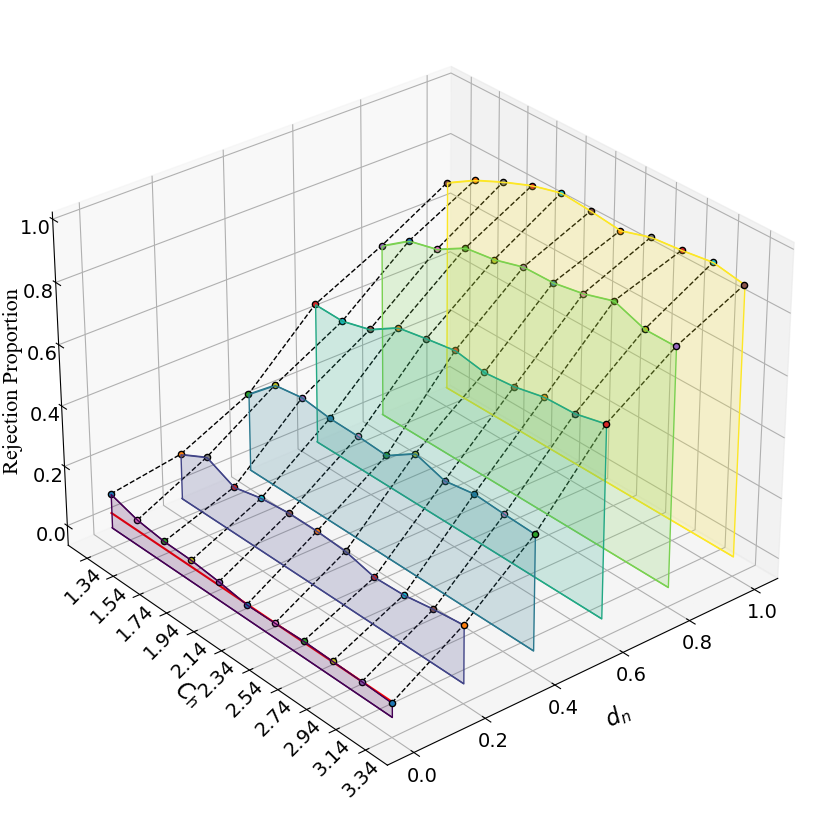

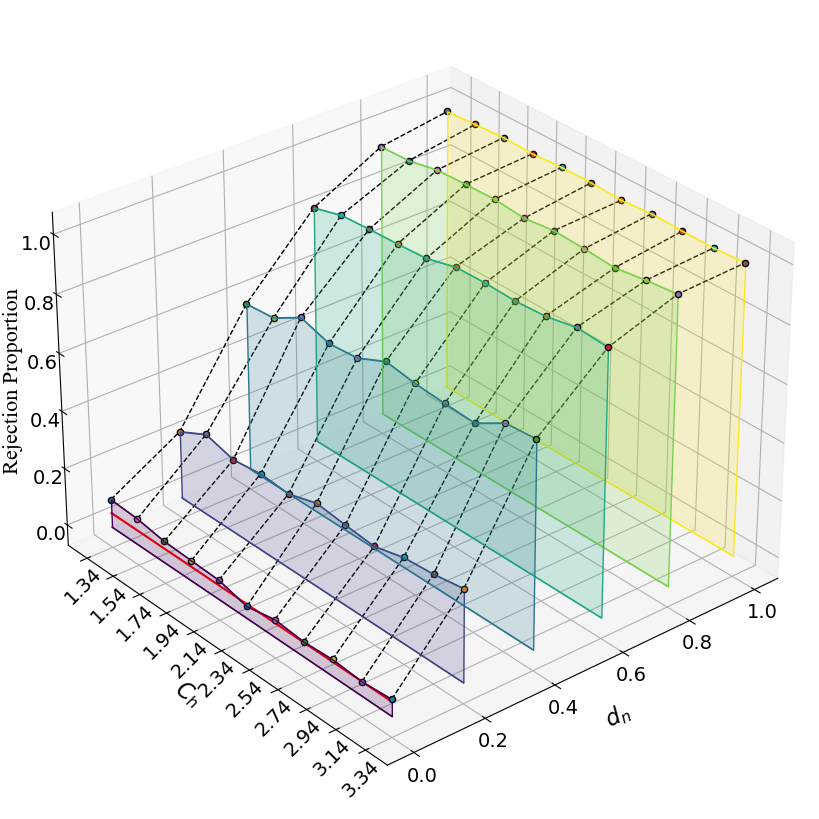

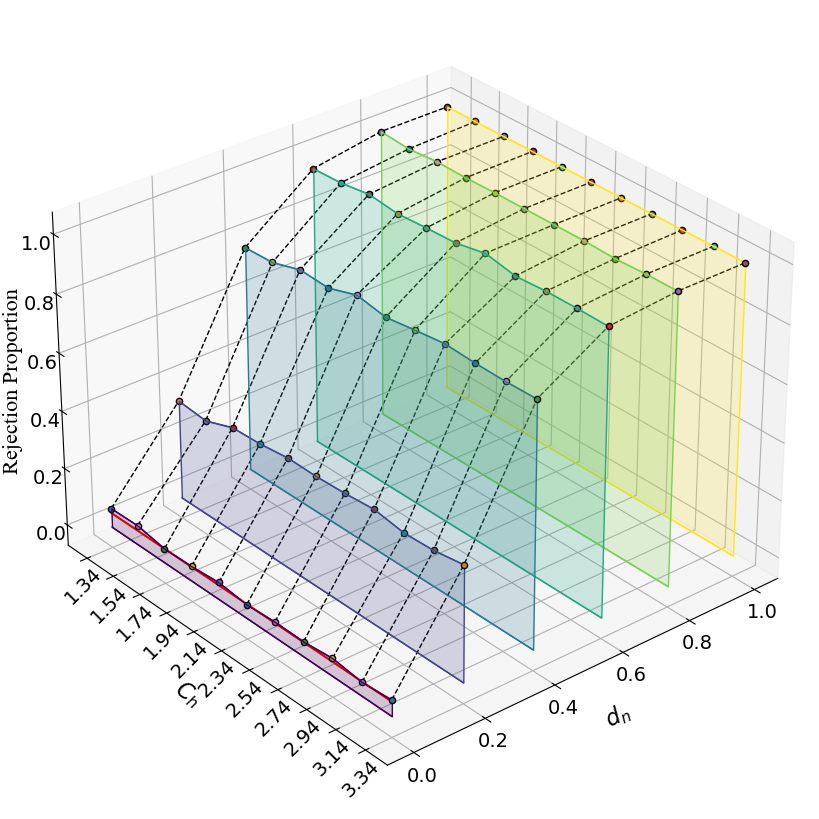

In [5]:
path1 = 'Exam1_exp'
mode = 'Homo'

path2 = path1 + '/Figures/'
file_name = path1 + '/' + path1 + '_' + mode + '.xls'
n_list = [100, 200, 300]
lams = [20, 40]
i = 0 # 0, 1
df = pd.read_excel(file_name, sheet_name = i, index_col= 0)
lam = lams[i] 
fontsize = 16
fontsize2 = 14
figure_show = True
plot_3d(df, path1, path2, mode, lam = lam, fontsize = fontsize, fontsize2 = fontsize2, figure_show = figure_show)

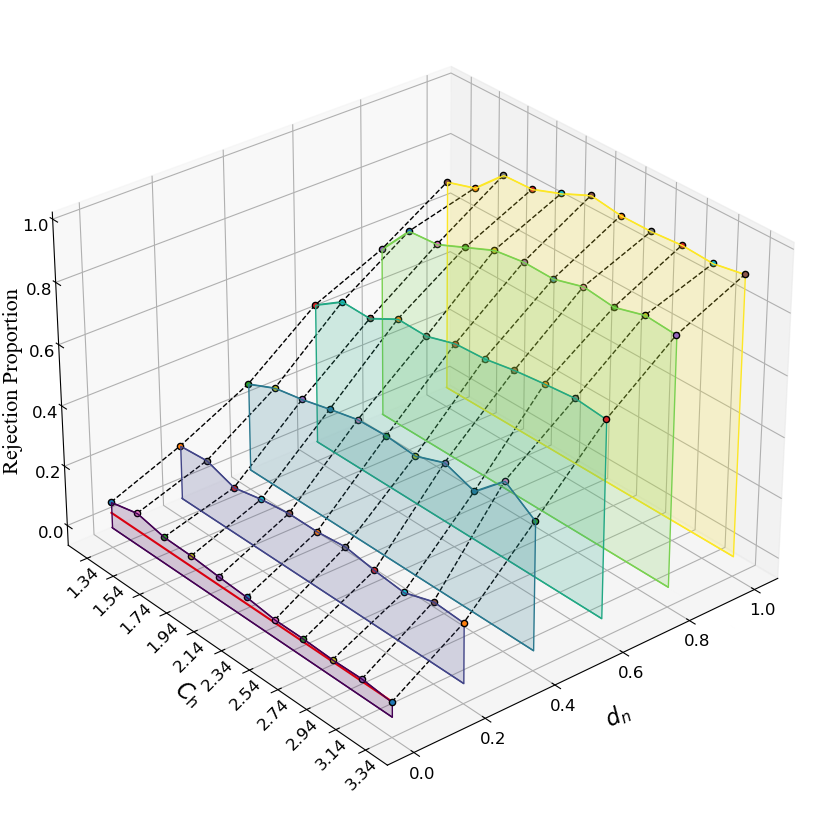

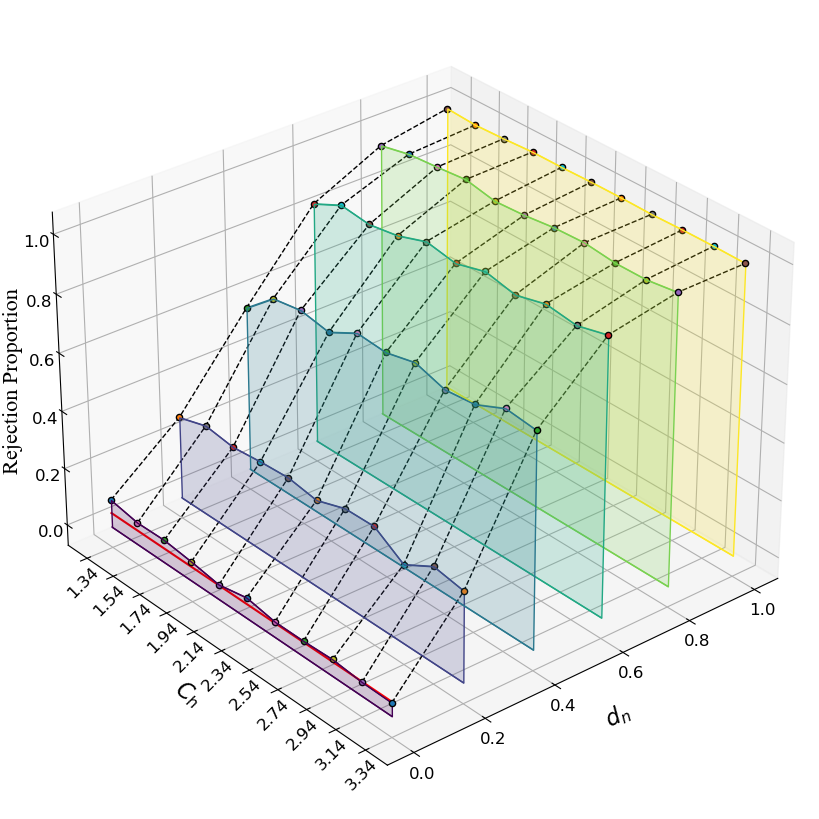

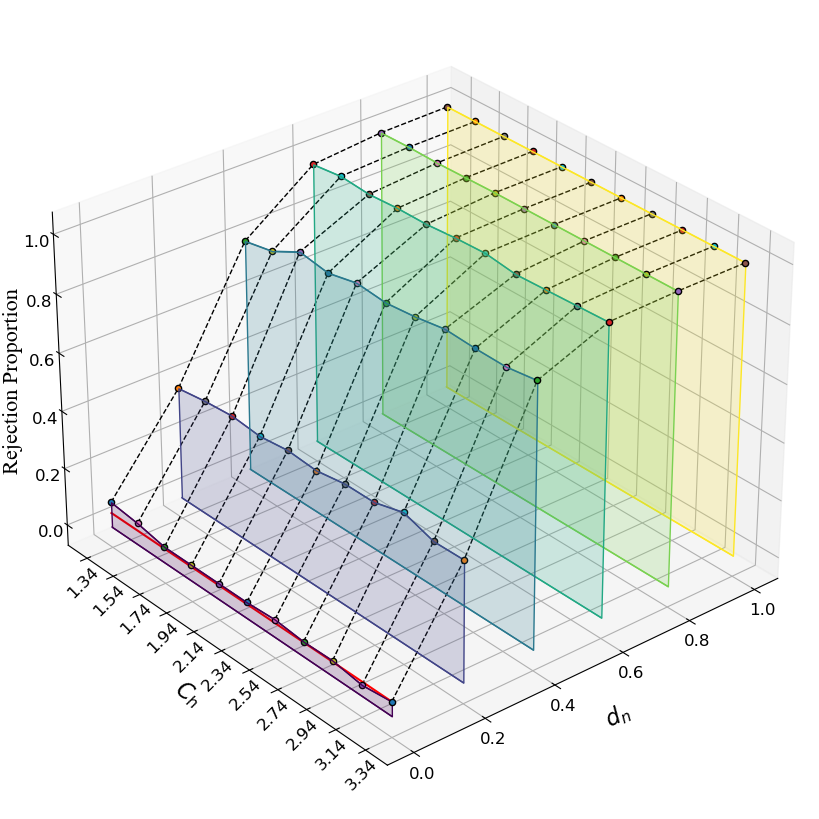

In [4]:
path1 = 'Exam1_exp'
mode = 'Homo'

path2 = path1 + '/Figures/'
file_name = path1 + '/' + path1 + '_' + mode + '.xls'
n_list = [100, 200, 300]
lams = [20, 40]
i = 1 # 0, 1
df = pd.read_excel(file_name, sheet_name = i, index_col= 0)
lam = lams[i] 
fontsize = 16
fontsize2 = 12
figure_show = True
plot_3d(df, path1, path2, mode, lam = lam, fontsize = fontsize, fontsize2 = fontsize2, figure_show = figure_show)

### Heter

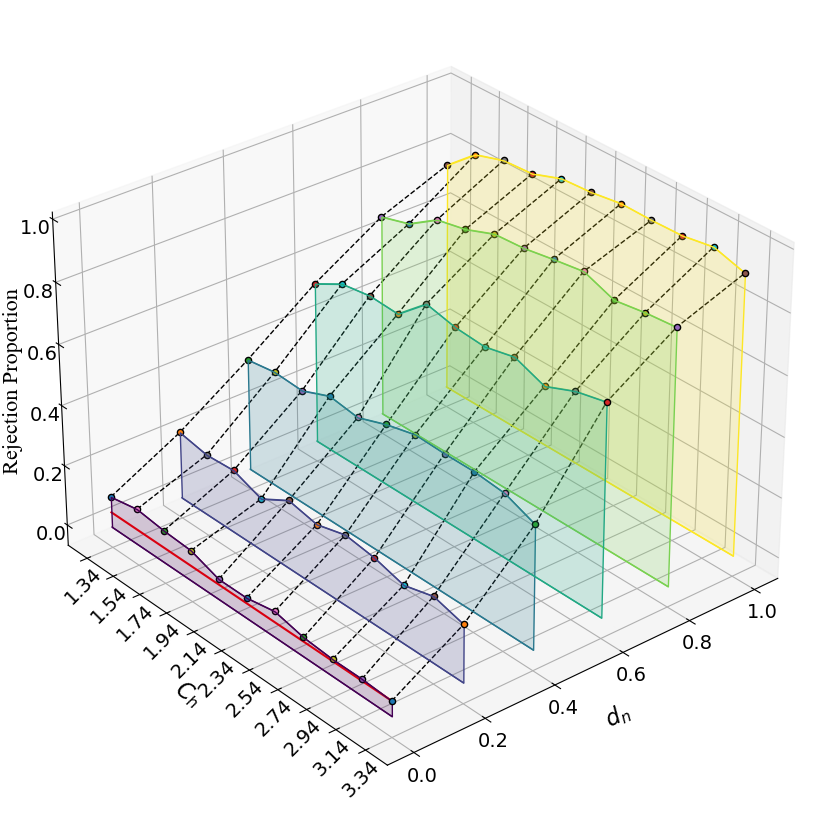

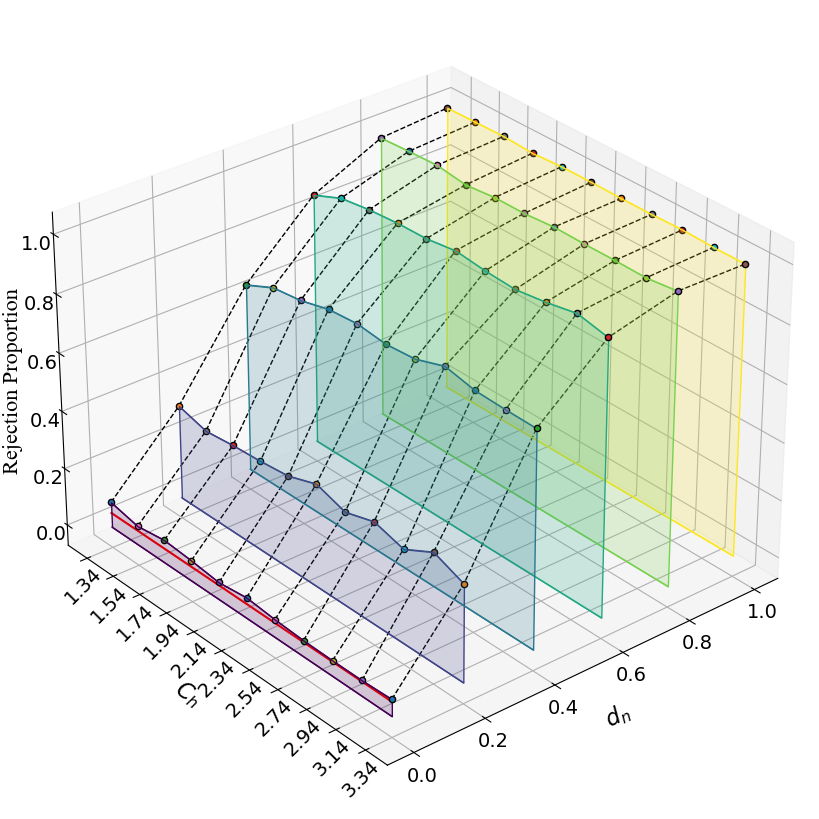

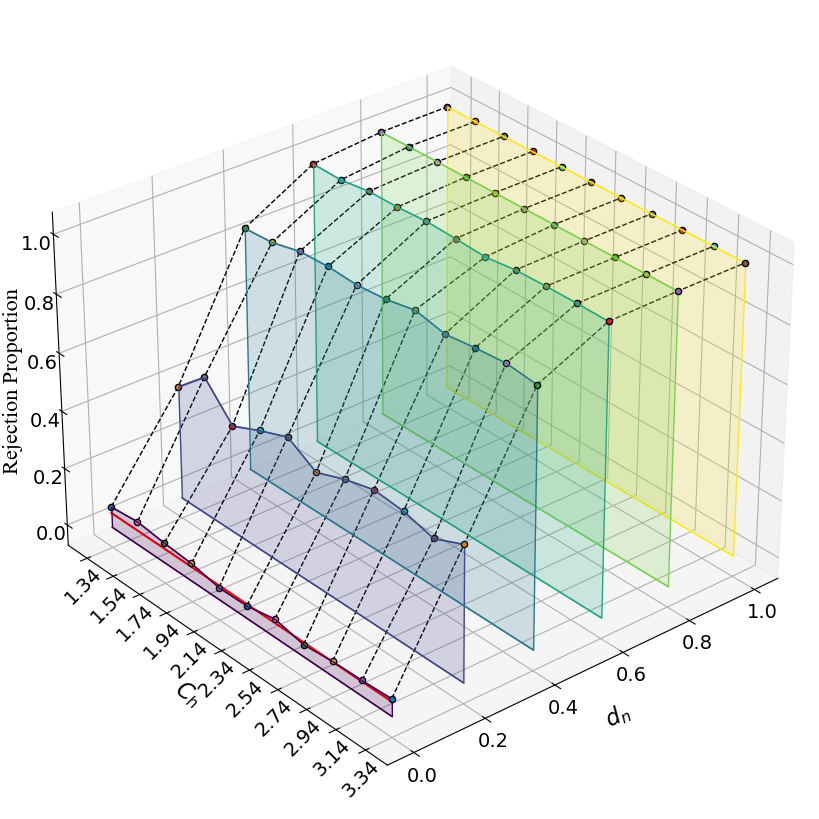

In [6]:
path1 = 'Exam1_exp'
mode = 'Heter'

path2 = path1 + '/Figures/'
file_name = path1 + '/' + path1 + '_' + mode + '.xls'
n_list = [100, 200, 300]
lams = [20, 40]
i = 0 # 0, 1
df = pd.read_excel(file_name, sheet_name = i, index_col= 0)
lam = lams[i] 
fontsize = 16
fontsize2 = 14
figure_show = True
plot_3d(df, path1, path2, mode, lam = lam, fontsize = fontsize, fontsize2 = fontsize2, figure_show = figure_show)

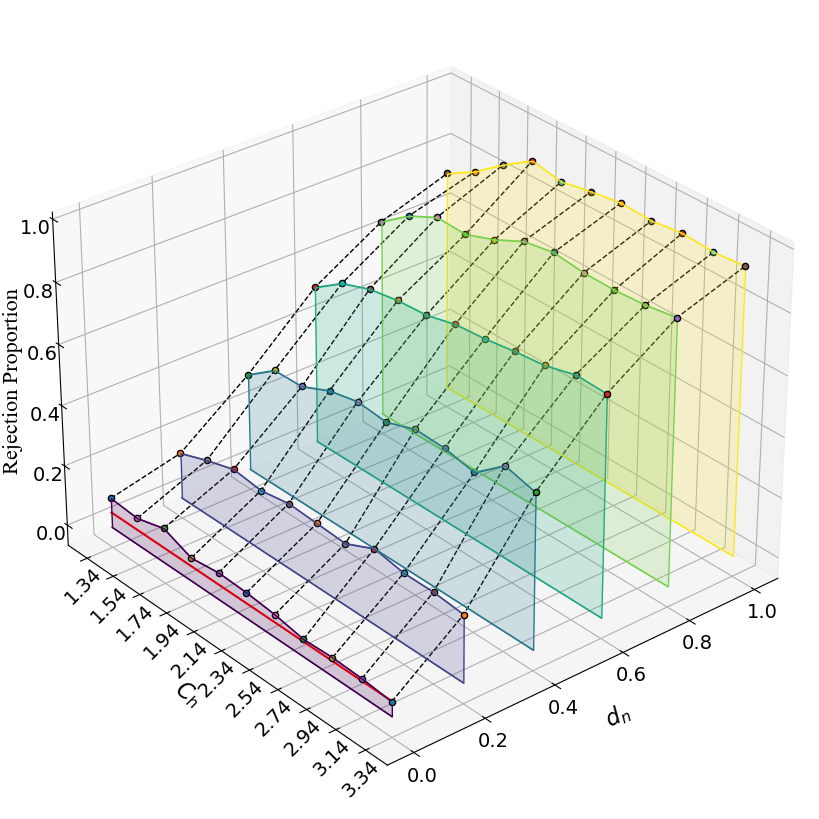

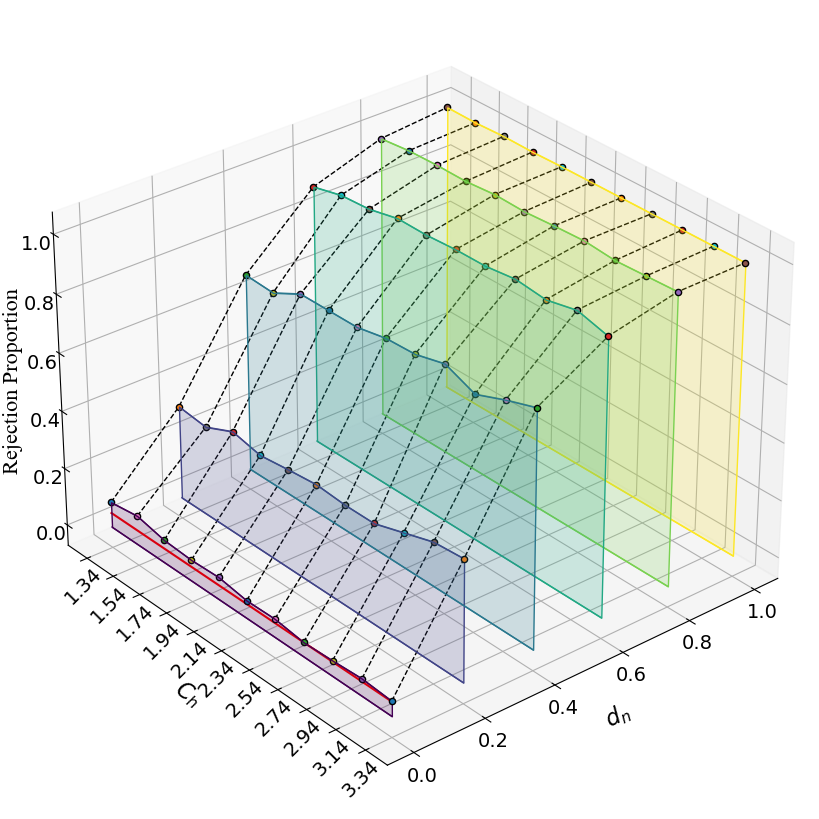

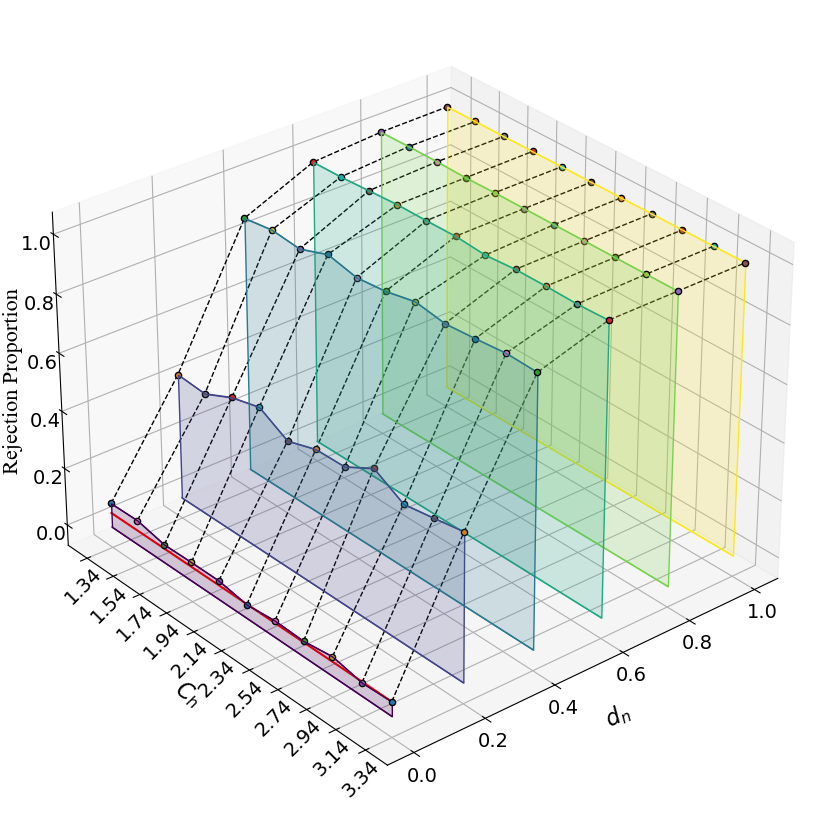

In [8]:
path1 = 'Exam1_exp'
mode = 'Heter'

path2 = path1 + '/Figures/'
file_name = path1 + '/' + path1 + '_' + mode + '.xls'
n_list = [100, 200, 300]
lams = [20, 40]
i = 1 # 0, 1
df = pd.read_excel(file_name, sheet_name = i, index_col= 0)
lam = lams[i] 
fontsize = 16
fontsize2 = 14
figure_show = True
plot_3d(df, path1, path2, mode, lam = lam, fontsize = fontsize, fontsize2 = fontsize2, figure_show = figure_show)

# Exam1-runif

### Homo

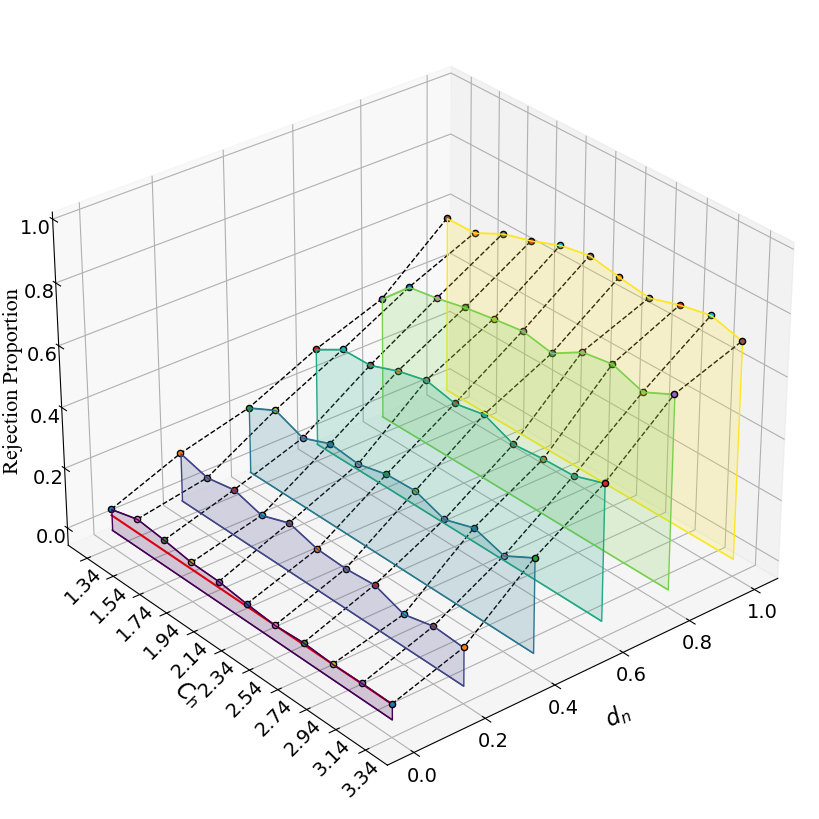

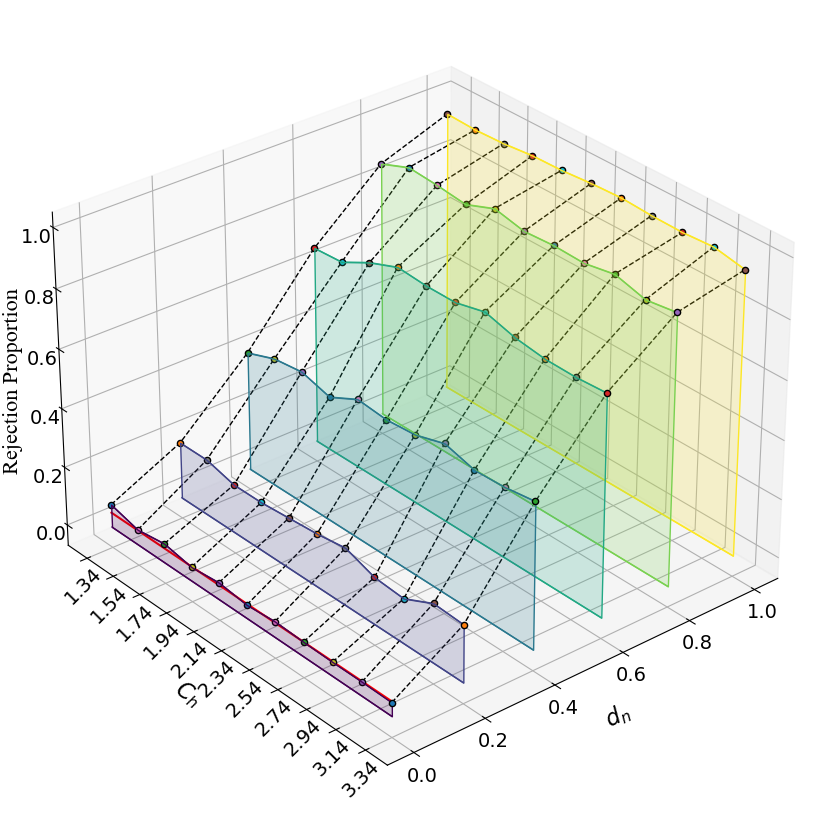

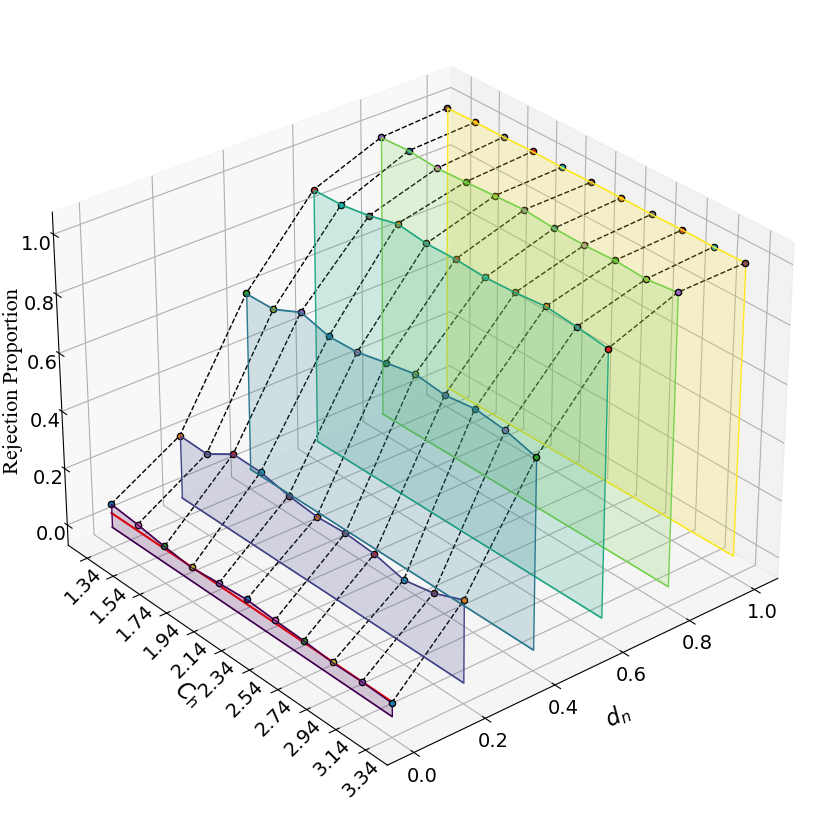

In [11]:
path1 = 'Exam1_unif'
mode = 'Homo'

path2 = path1 + '/Figures/'
file_name = path1 + '/' + path1 + '_' + mode + '.xls'
n_list = [100, 200, 300]
lams = [20, 40]
i = 0 # 0, 1
df = pd.read_excel(file_name, sheet_name = i, index_col= 0)
lam = lams[i] 
fontsize = 16
fontsize2 = 14
figure_show = True
plot_3d(df, path1, path2, mode, lam = lam, fontsize = fontsize, fontsize2 = fontsize2, figure_show = figure_show)

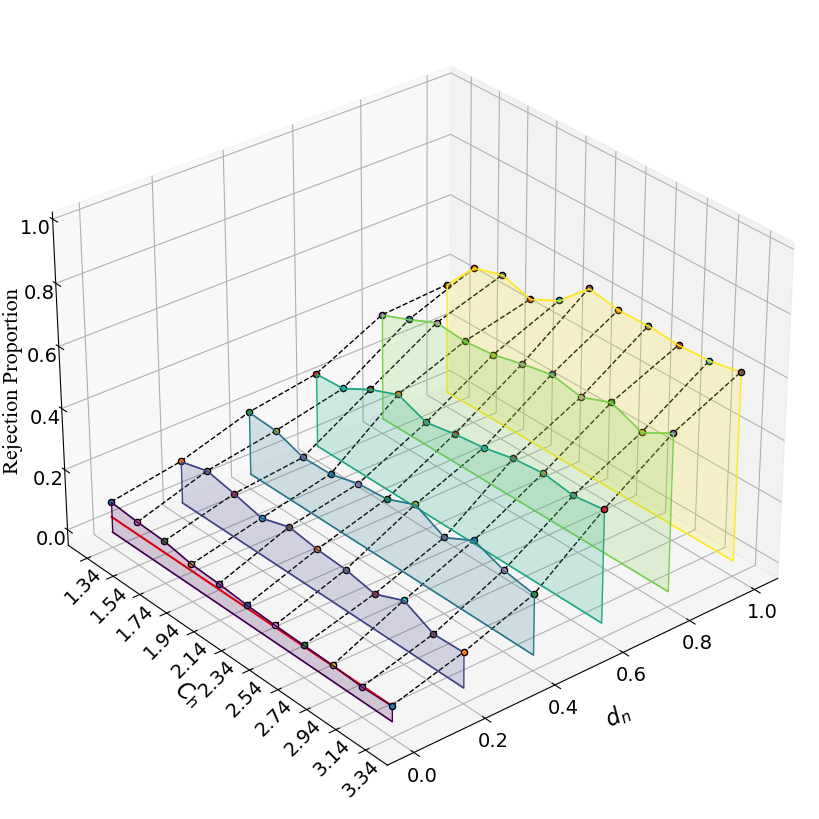

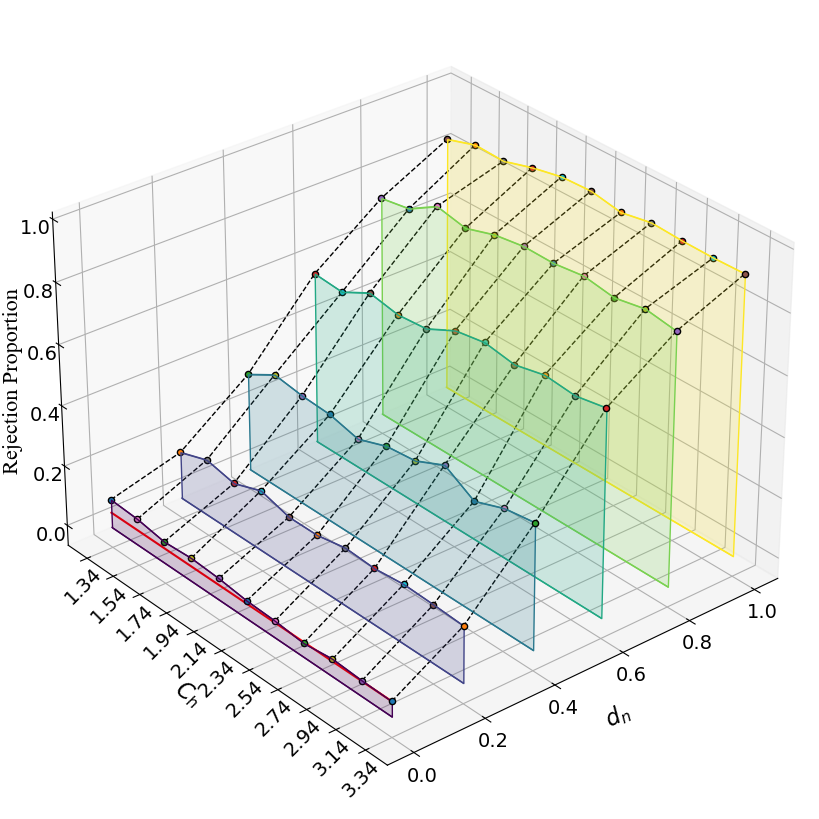

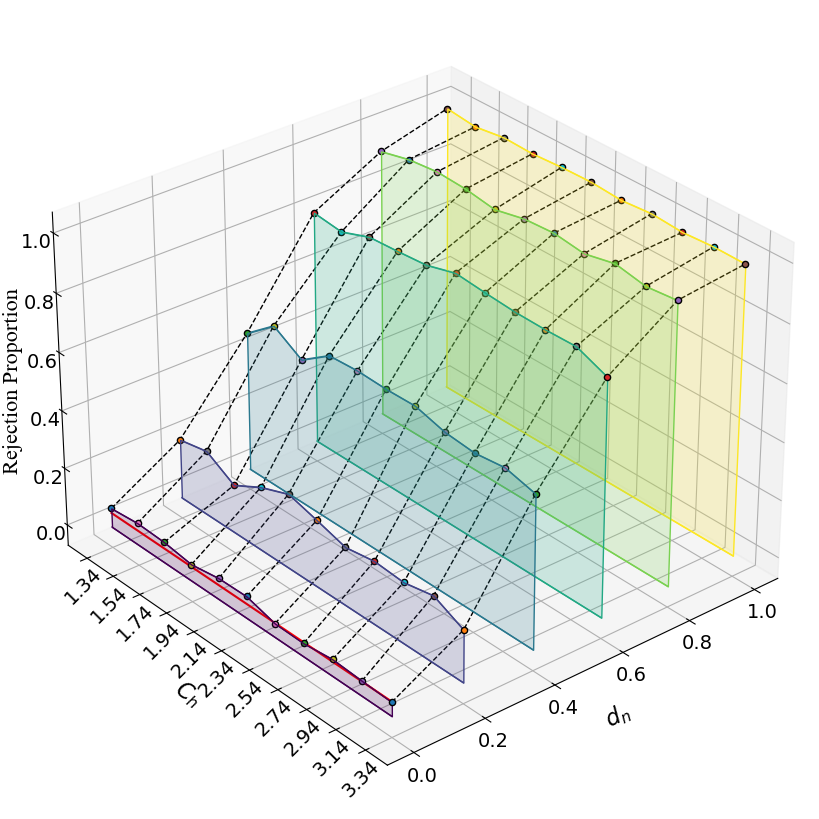

In [12]:
path1 = 'Exam1_unif'
mode = 'Homo'

path2 = path1 + '/Figures/'
file_name = path1 + '/' + path1 + '_' + mode + '.xls'
n_list = [100, 200, 300]
lams = [20, 40]
i = 1 # 0, 1
df = pd.read_excel(file_name, sheet_name = i, index_col= 0)
lam = lams[i] 
fontsize = 16
fontsize2 = 14
figure_show = True
plot_3d(df, path1, path2, mode, lam = lam, fontsize = fontsize, fontsize2 = fontsize2, figure_show = figure_show)

### Heter

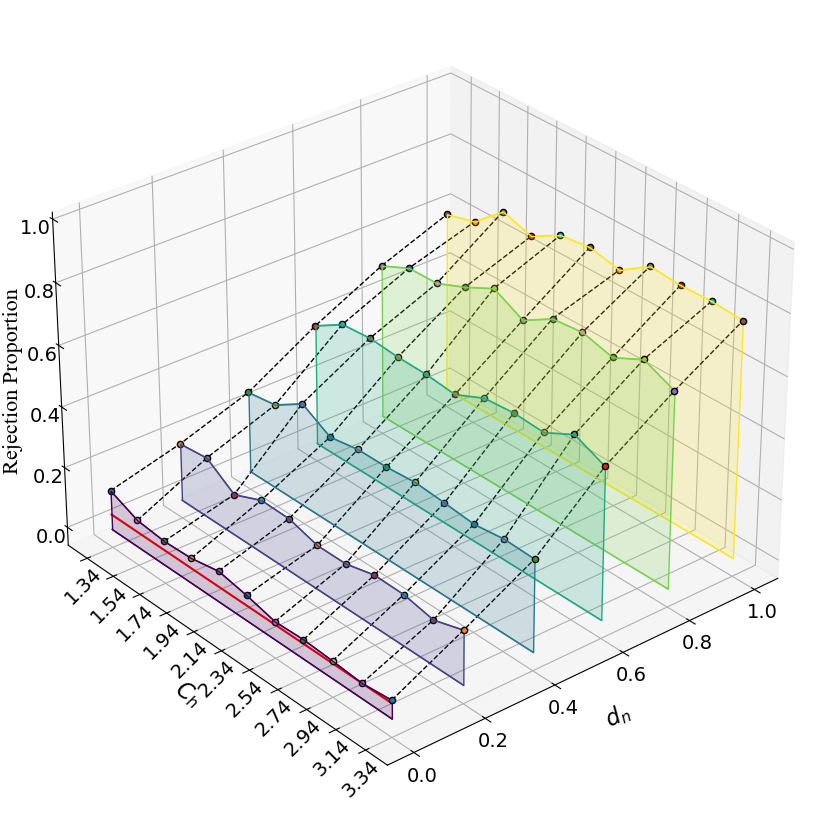

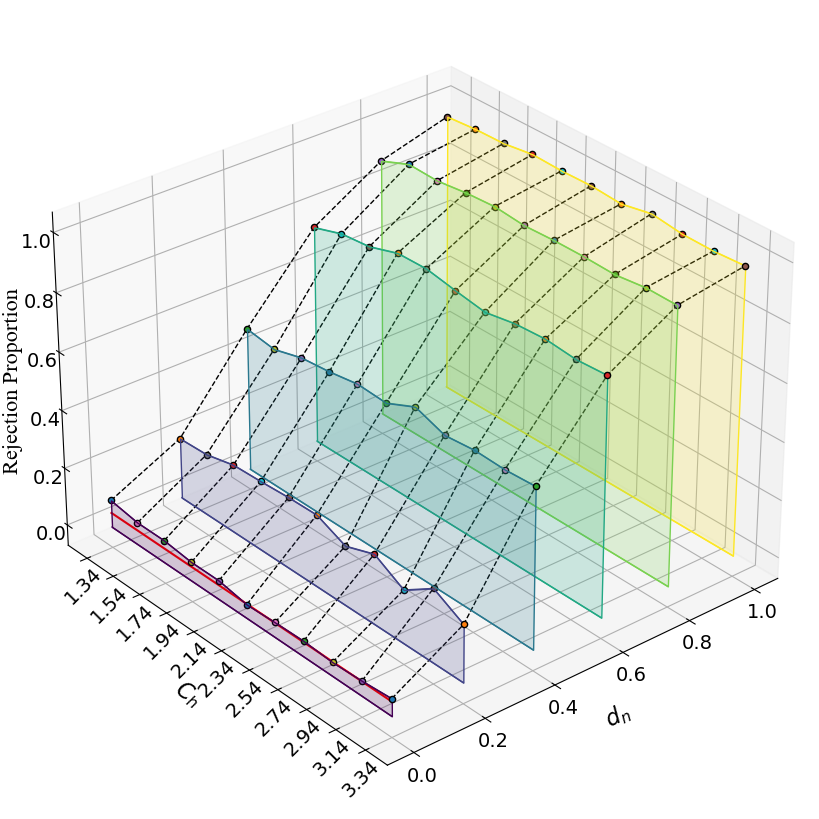

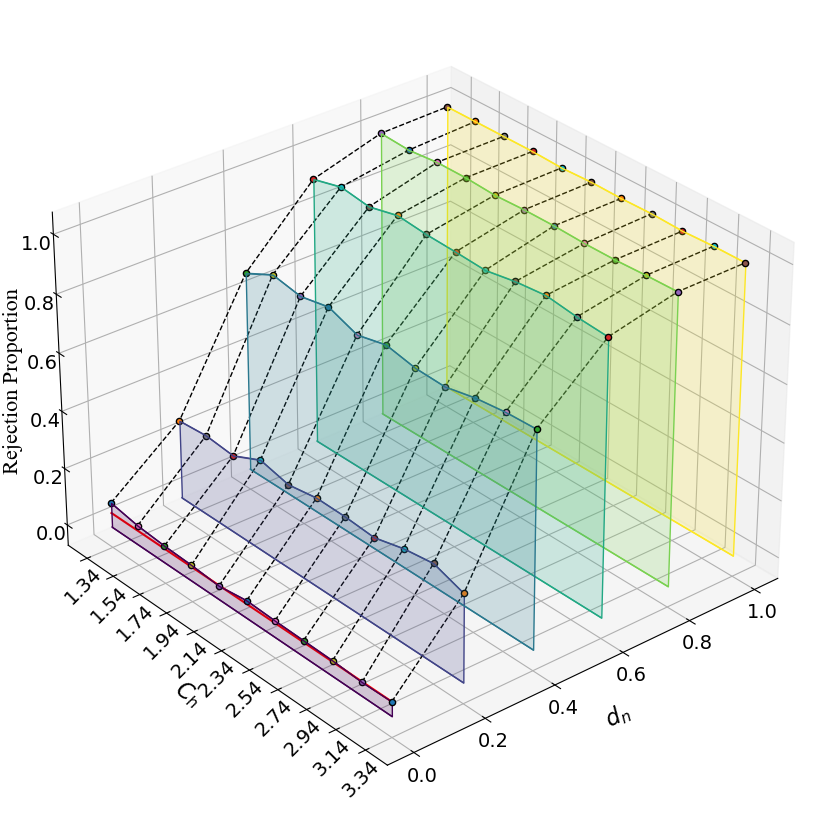

In [13]:
path1 = 'Exam1_unif'
mode = 'Heter'

path2 = path1 + '/Figures/'
file_name = path1 + '/' + path1 + '_' + mode + '.xls'
n_list = [100, 200, 300]
lams = [20, 40]
i = 0 # 0, 1
df = pd.read_excel(file_name, sheet_name = i, index_col= 0)
lam = lams[i] 
fontsize = 16
fontsize2 = 14
figure_show = True
plot_3d(df, path1, path2, mode, lam = lam, fontsize = fontsize, fontsize2 = fontsize2, figure_show = figure_show)

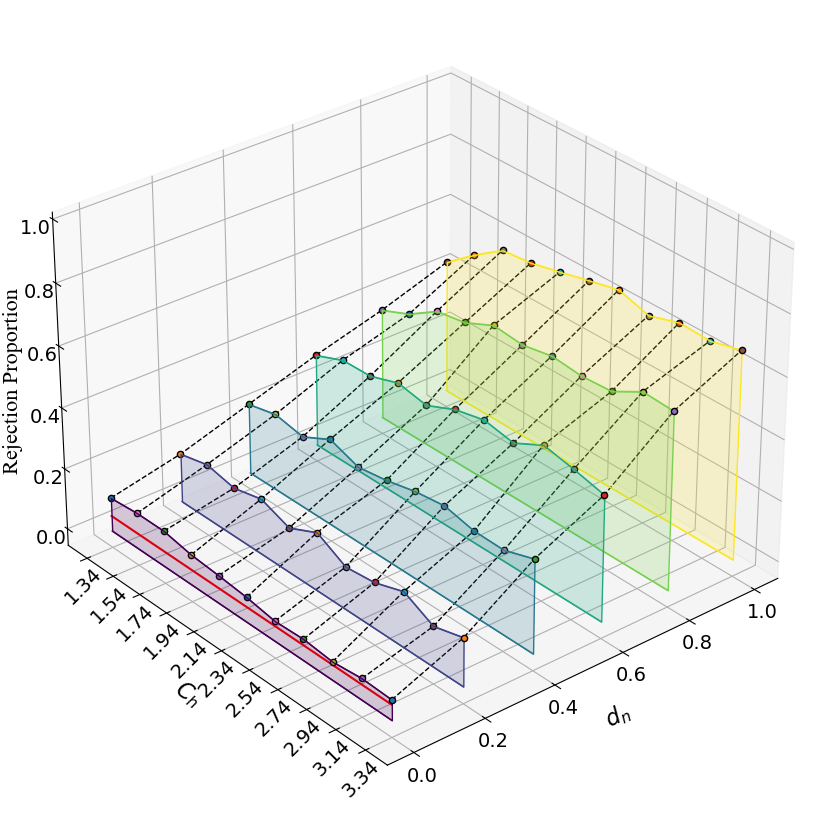

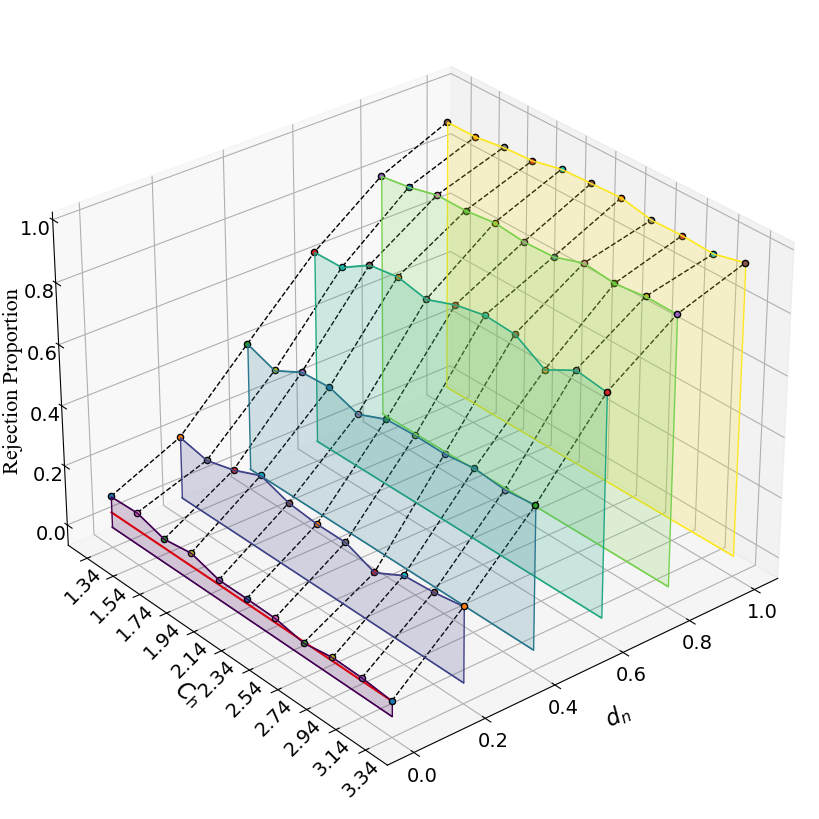

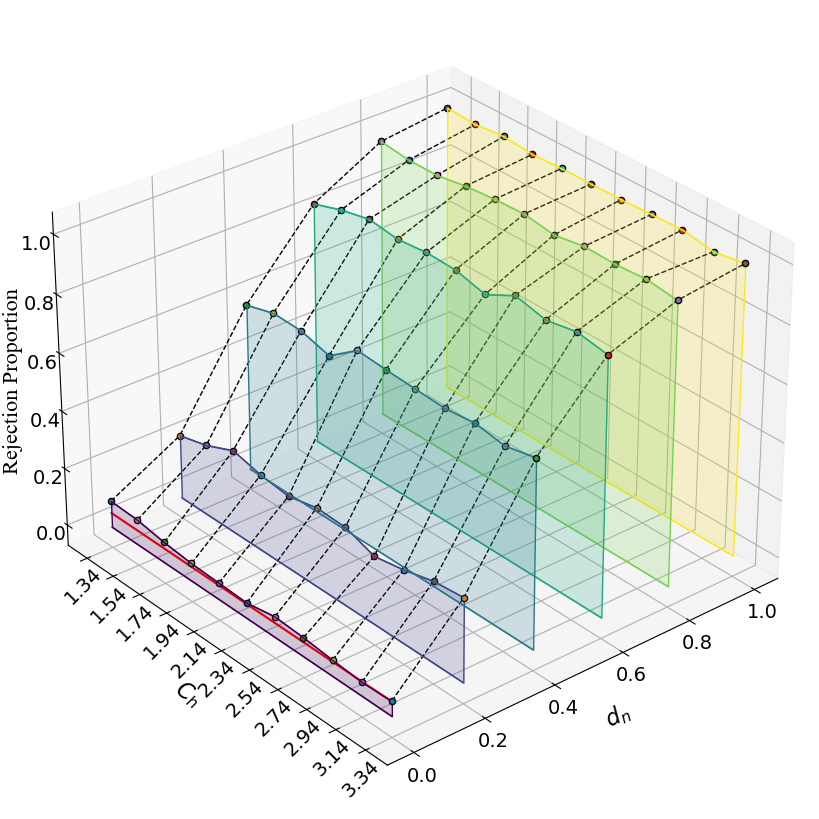

In [14]:
path1 = 'Exam1_unif'
mode = 'Heter'

path2 = path1 + '/Figures/'
file_name = path1 + '/' + path1 + '_' + mode + '.xls'
n_list = [100, 200, 300]
lams = [20, 40]
i = 1 # 0, 1
df = pd.read_excel(file_name, sheet_name = i, index_col= 0)
lam = lams[i] 
fontsize = 16
fontsize2 = 14
figure_show = True
plot_3d(df, path1, path2, mode, lam = lam, fontsize = fontsize, fontsize2 = fontsize2, figure_show = figure_show)

# Exam2

### Homo

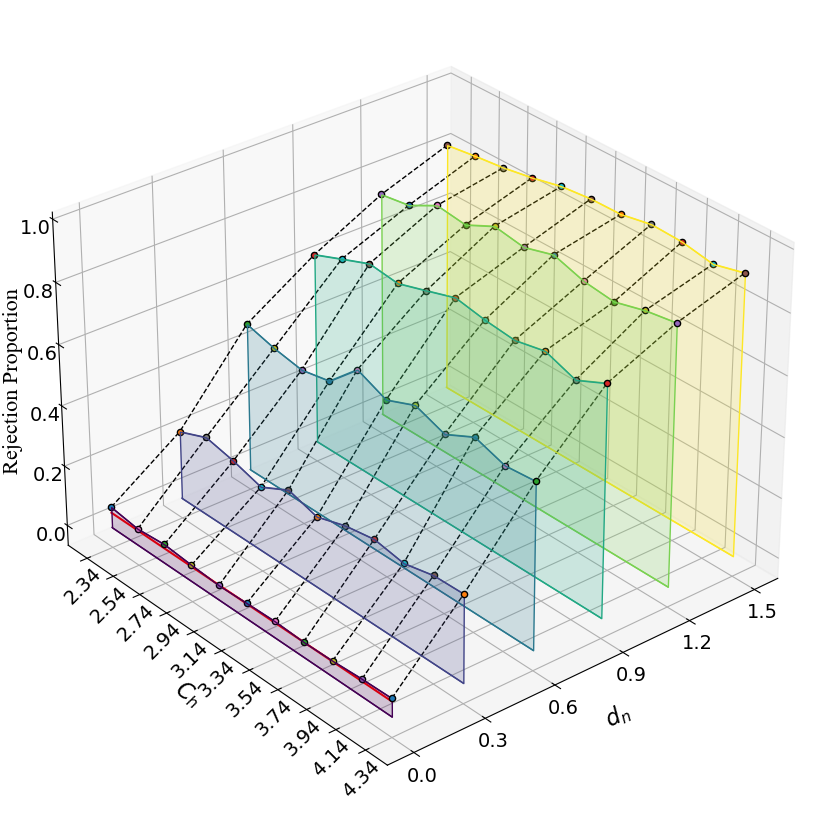

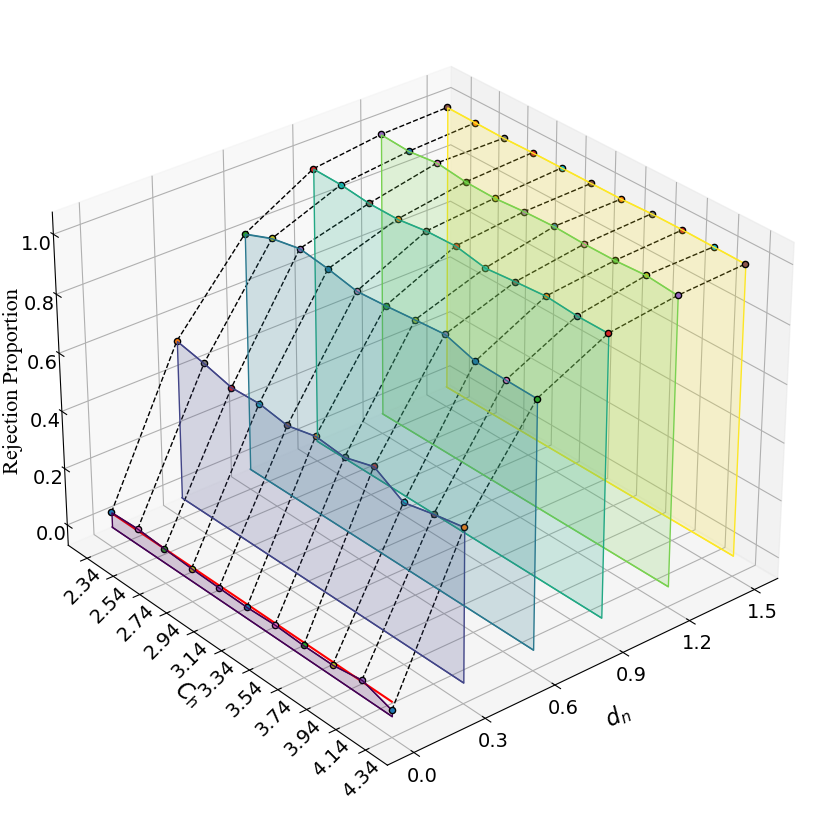

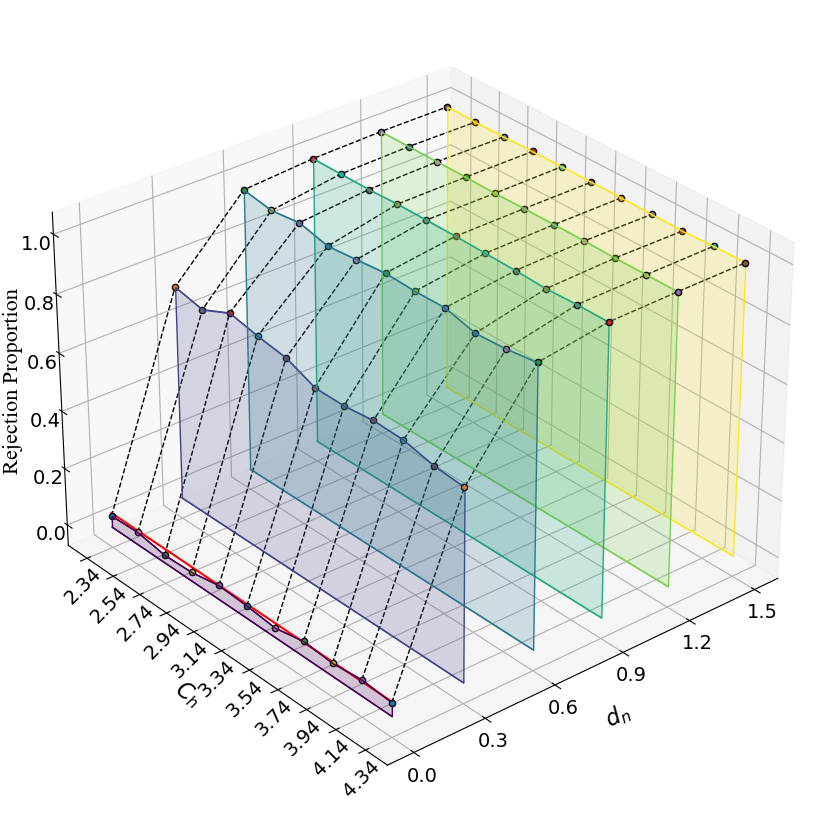

In [15]:
path1 = 'Exam2'
mode = 'Homo'

path2 = path1 + '/Figures/'
file_name = path1 + '/' + path1 + '_' + mode + '.xls'
n_list = [100, 200, 300]
lams = [20, 40]
i = 0 # 0, 1
df = pd.read_excel(file_name, sheet_name = i, index_col= 0)
lam = lams[i] 
fontsize = 16
fontsize2 = 14
figure_show = True
plot_3d(df, path1, path2, mode, lam = lam, fontsize = fontsize, fontsize2 = fontsize2, figure_show = figure_show)

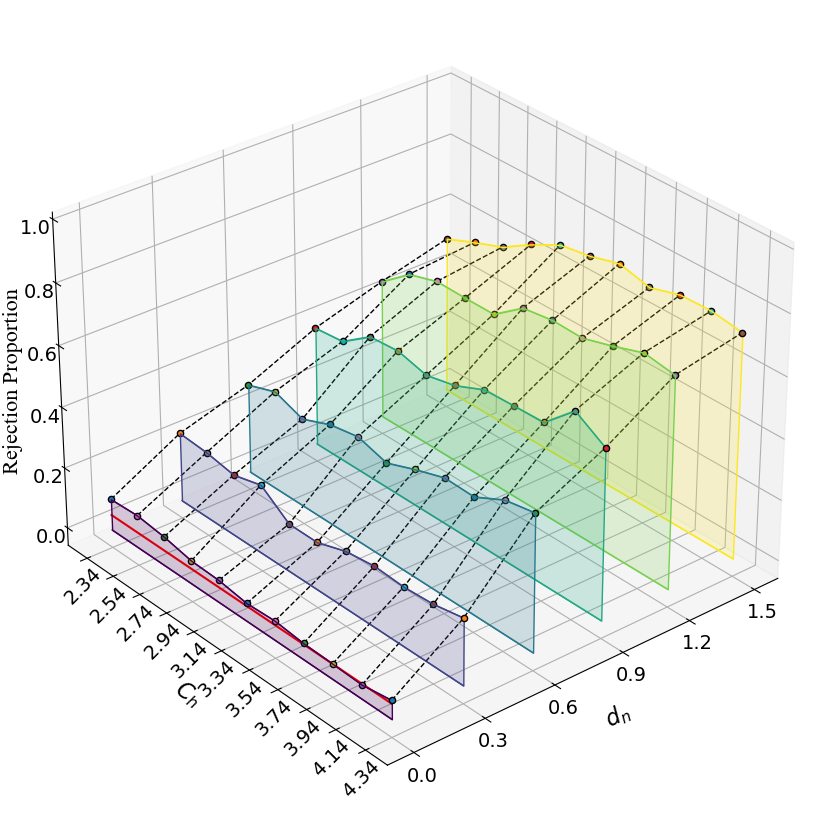

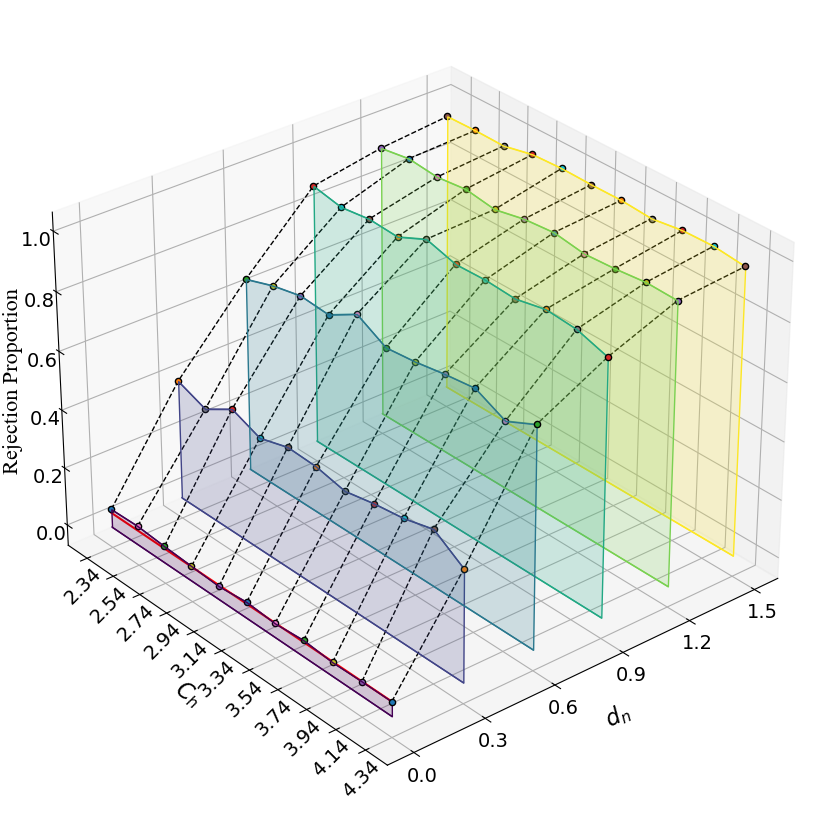

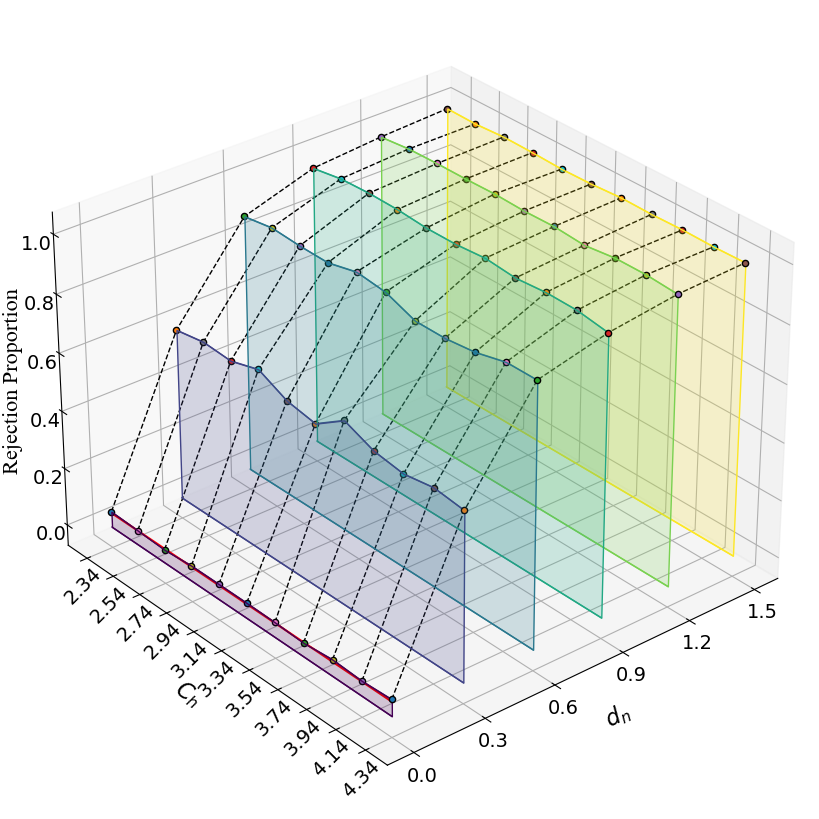

In [16]:
path1 = 'Exam2'
mode = 'Homo'

path2 = path1 + '/Figures/'
file_name = path1 + '/' + path1 + '_' + mode + '.xls'
n_list = [100, 200, 300]
lams = [20, 40]
i = 1 # 0, 1
df = pd.read_excel(file_name, sheet_name = i, index_col= 0)
lam = lams[i] 
fontsize = 16
fontsize2 = 14
figure_show = True
plot_3d(df, path1, path2, mode, lam = lam, fontsize = fontsize, fontsize2 = fontsize2, figure_show = figure_show)

### Heter

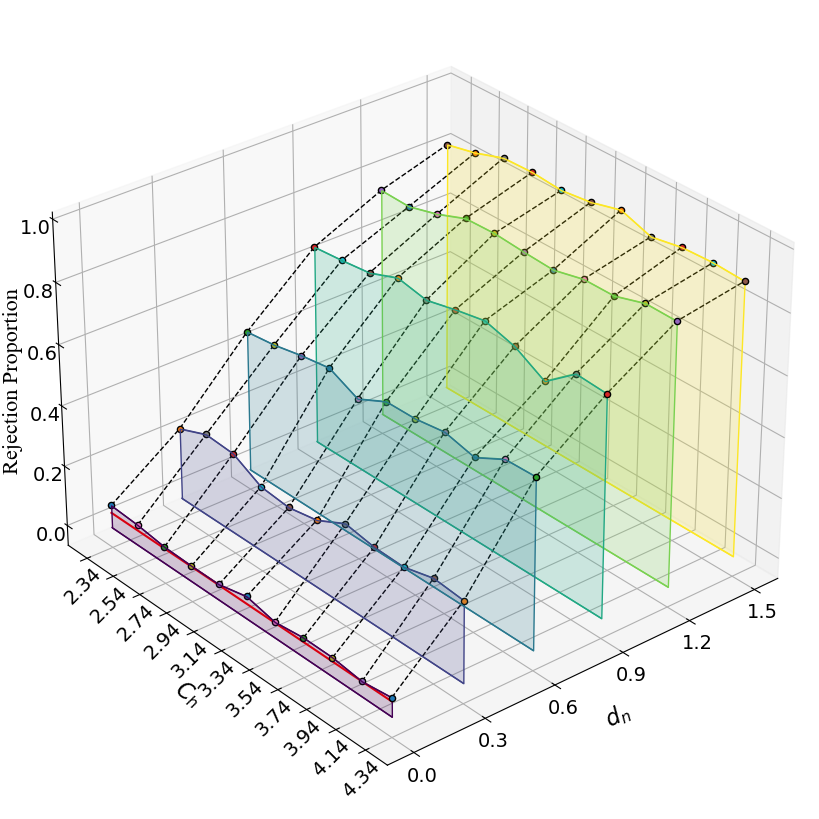

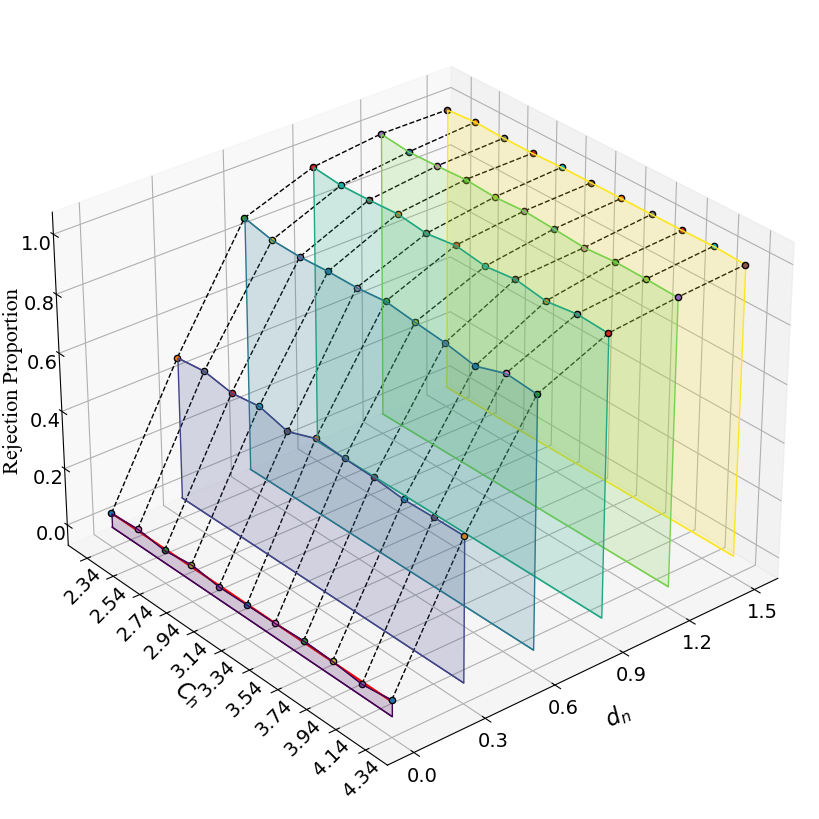

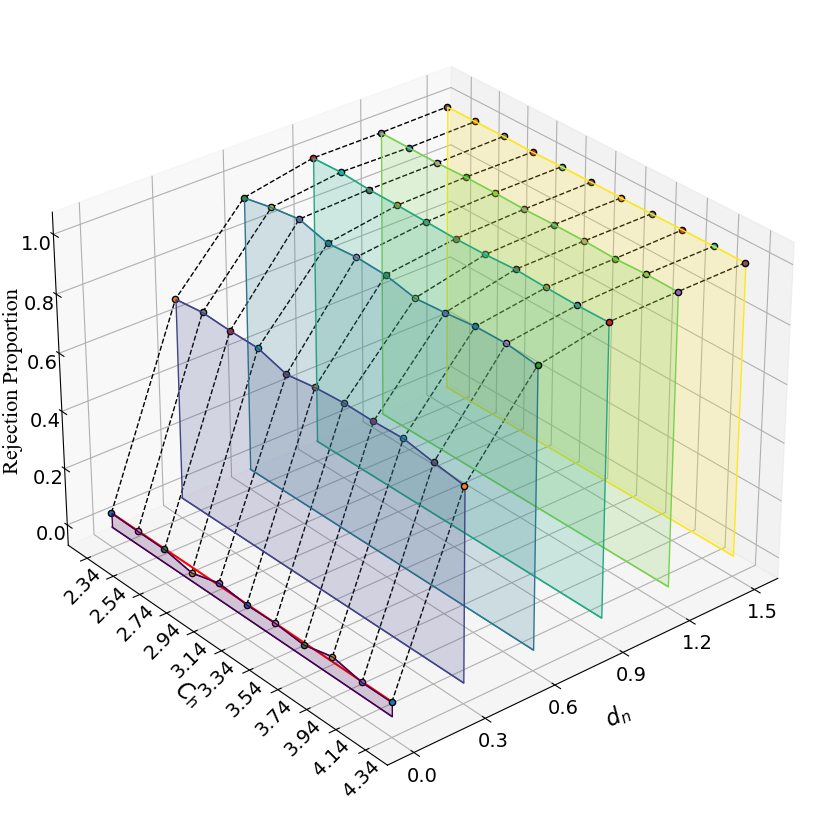

In [17]:
path1 = 'Exam2'
mode = 'Heter'

path2 = path1 + '/Figures/'
file_name = path1 + '/' + path1 + '_' + mode + '.xls'
n_list = [100, 200, 300]
lams = [20, 40]
i = 0 # 0, 1
df = pd.read_excel(file_name, sheet_name = i, index_col= 0)
lam = lams[i] 
fontsize = 16
fontsize2 = 14
figure_show = True
plot_3d(df, path1, path2, mode, lam = lam, fontsize = fontsize, fontsize2 = fontsize2, figure_show = figure_show)

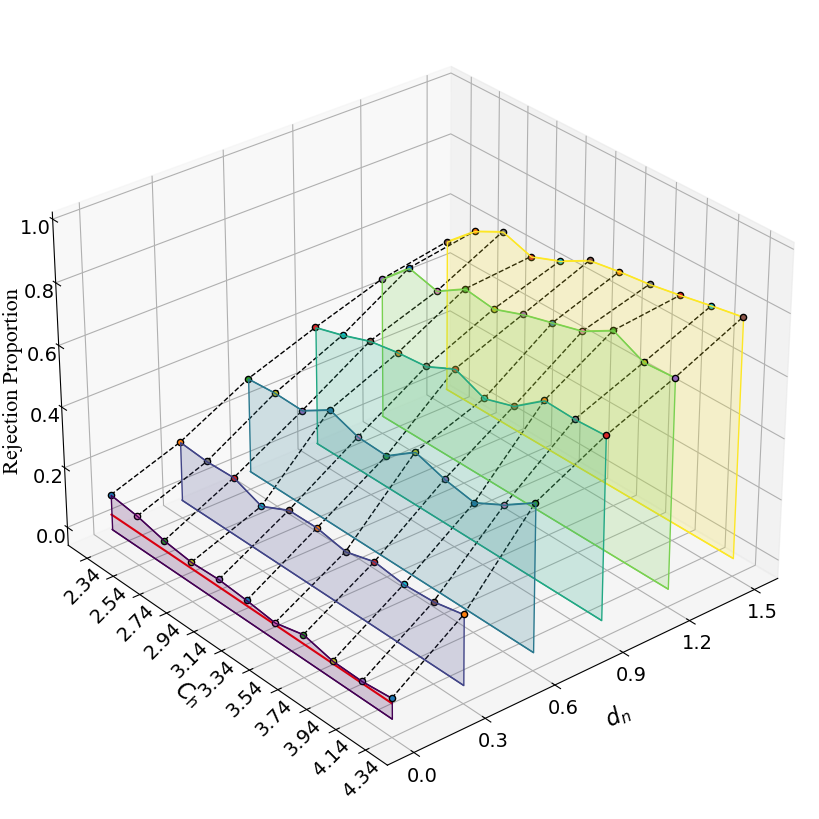

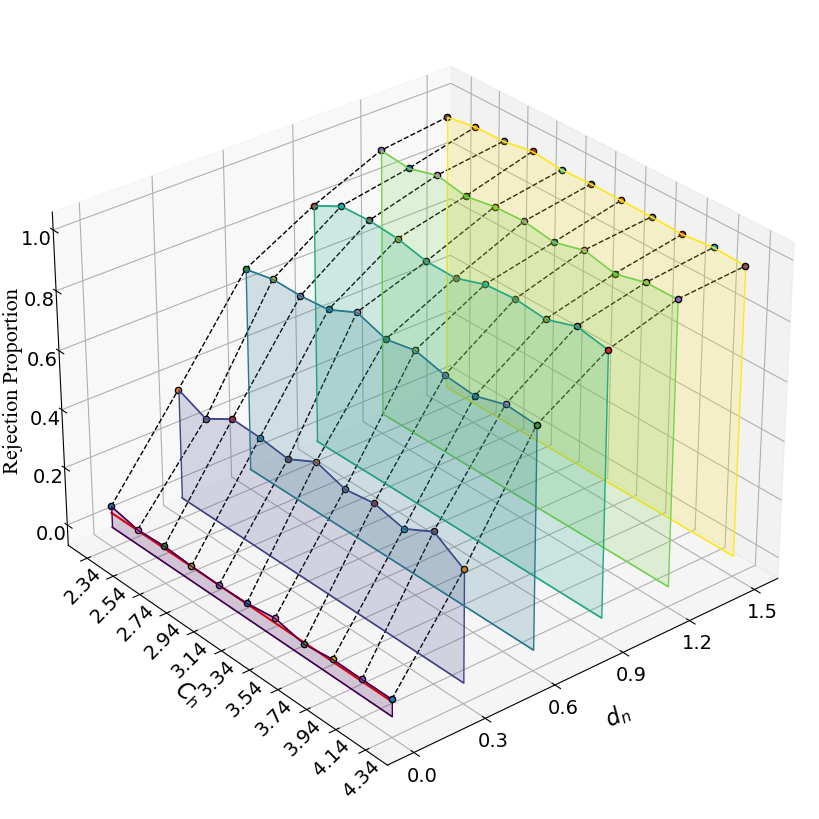

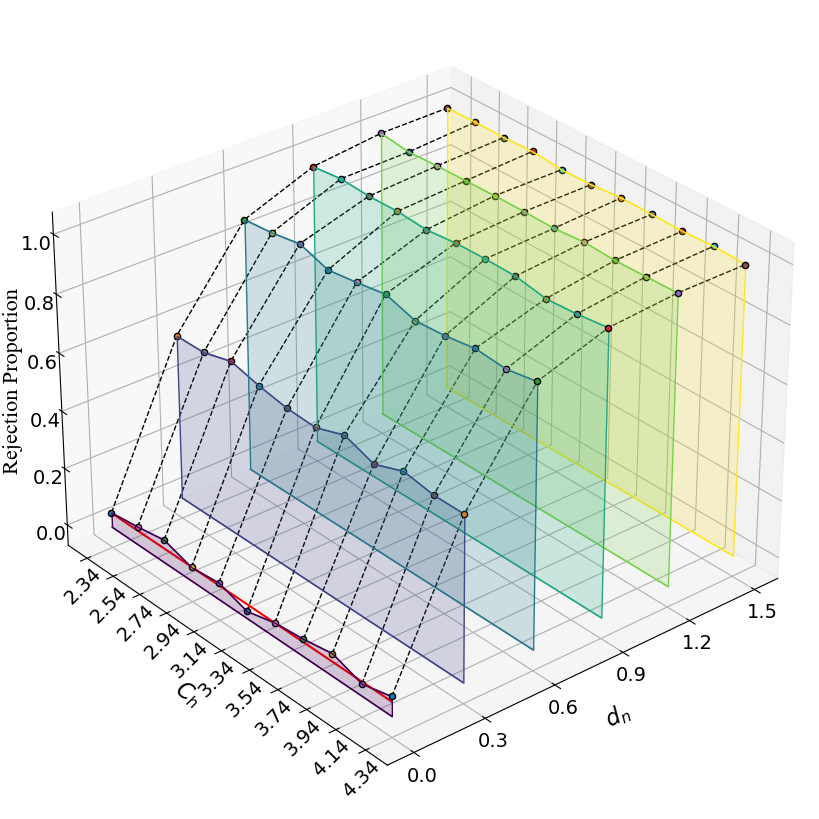

In [18]:
path1 = 'Exam2'
mode = 'Heter'

path2 = path1 + '/Figures/'
file_name = path1 + '/' + path1 + '_' + mode + '.xls'
n_list = [100, 200, 300]
lams = [20, 40]
i = 1 # 0, 1
df = pd.read_excel(file_name, sheet_name = i, index_col= 0)
lam = lams[i] 
fontsize = 16
fontsize2 = 14
figure_show = True
plot_3d(df, path1, path2, mode, lam = lam, fontsize = fontsize, fontsize2 = fontsize2, figure_show = figure_show)